# Experiment 1 — Exploratory Data Analysis (EDA)

**Aim:** Perform exploratory data analysis on the Titanic passenger dataset: inspect structure and types, handle missing values, compute summary statistics and category counts, examine correlations, and draw conclusions about survival patterns.

**Description:** Exploratory Data Analysis is the first step of any data science project. Before building a model, we look at the data to understand its structure, spot missing values and outliers, and discover patterns and relationships between columns. Summary statistics such as mean, median and standard deviation, together with correlation checks, tell us which features look useful and which need cleaning.

**Dataset:** Titanic passenger dataset (local copy: `datasets/titanic_data.csv`, 891 passengers — the same data as the [seaborn titanic CSV](https://raw.githubusercontent.com/mwaskom/seaborn-data/master/titanic.csv) referenced in the manual).

In [1]:
%matplotlib inline
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

for candidate in [Path("datasets"), Path("../datasets")]:
    if candidate.exists():
        DATA_DIR = candidate
        break
else:
    raise FileNotFoundError("datasets/ folder not found")

for candidate in [Path("outputs"), Path("../outputs")]:
    if candidate.exists():
        OUTPUT_DIR = candidate
        break

FIG_DIR = OUTPUT_DIR / "figures"
RES_DIR = OUTPUT_DIR / "results"
FIG_DIR.mkdir(parents=True, exist_ok=True)
RES_DIR.mkdir(parents=True, exist_ok=True)

## 1. Load the dataset — shape, column types and first rows

In [2]:
df = pd.read_csv(DATA_DIR / "titanic_data.csv")

print("Shape (rows, columns):", df.shape)
print("\nColumn types:")
print(df.dtypes)
df.head()

Shape (rows, columns): (891, 12)

Column types:
PassengerId      int64
Survived         int64
Pclass           int64
Name            object
Sex             object
Age            float64
SibSp            int64
Parch            int64
Ticket          object
Fare           float64
Cabin           object
Embarked        object
dtype: object


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Missing values

For each column we count the missing entries. Handling strategy:

- **Age** (177 missing): fill with the median age — a robust centre that is not pulled by outliers.
- **Embarked** (2 missing): fill with the mode (most common port).
- **Cabin** (687 missing, ~77%): too missing to be useful, so the column is dropped.
- `PassengerId` and `Name`/`Ticket` are identifiers, kept for reference but not used numerically.

In [3]:
missing = df.isna().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_table = pd.DataFrame({"Missing count": missing, "Missing %": missing_pct})
print(missing_table[missing_table["Missing count"] > 0])

df["Age"] = df["Age"].fillna(df["Age"].median())
df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
df = df.drop(columns=["Cabin"])

print("\nMissing values after handling:")
print(df.isna().sum().sum(), "missing values remaining")

          Missing count  Missing %
Age                 177      19.87
Cabin               687      77.10
Embarked              2       0.22

Missing values after handling:
0 missing values remaining


## 3. Summary statistics and category counts

In [4]:
df.describe()

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
count,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000,891.000000
mean,446.000000,0.383838,2.308642,29.361582,0.523008,0.381594,32.204208
std,257.353842,0.486592,0.836071,13.019697,1.102743,0.806057,49.693429
min,1.000000,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,223.500000,0.000000,2.000000,22.000000,0.000000,0.000000,7.910400
50%,446.000000,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,668.500000,1.000000,3.000000,35.000000,1.000000,0.000000,31.000000
max,891.000000,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [5]:
categorical_cols = ["Survived", "Pclass", "Sex", "SibSp", "Parch", "Embarked"]
for col in categorical_cols:
    print(f"Value counts for {col}:")
    print(df[col].value_counts())
    print()

Value counts for Survived:
Survived
0    549
1    342
Name: count, dtype: int64

Value counts for Pclass:
Pclass
3    491
1    216
2    184
Name: count, dtype: int64

Value counts for Sex:
Sex
male      577
female    314
Name: count, dtype: int64

Value counts for SibSp:
SibSp
0    608
1    209
2     28
4     18
3     16
8      7
5      5
Name: count, dtype: int64

Value counts for Parch:
Parch
0    678
1    118
2     80
5      5
3      5
4      4
6      1
Name: count, dtype: int64

Value counts for Embarked:
Embarked
S    646
C    168
Q     77
Name: count, dtype: int64



## 4. Correlation matrix and survival patterns

The heatmap below shows linear correlations among the numeric columns. Survival rates are then broken down by sex and passenger class — the two categorical patterns the manual highlights.

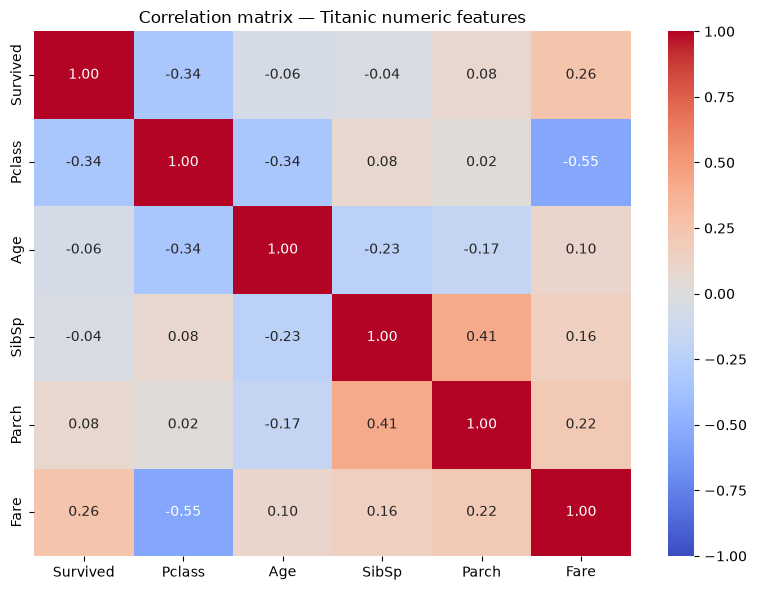

          Survived  Pclass    Age  SibSp  Parch   Fare
Survived     1.000  -0.338 -0.065 -0.035  0.082  0.257
Pclass      -0.338   1.000 -0.340  0.083  0.018 -0.549
Age         -0.065  -0.340  1.000 -0.233 -0.172  0.097
SibSp       -0.035   0.083 -0.233  1.000  0.415  0.160
Parch        0.082   0.018 -0.172  0.415  1.000  0.216
Fare         0.257  -0.549  0.097  0.160  0.216  1.000


In [6]:
corr = df[["Survived", "Pclass", "Age", "SibSp", "Parch", "Fare"]].corr()

plt.figure(figsize=(8, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1)
plt.title("Correlation matrix — Titanic numeric features")
plt.tight_layout()
plt.savefig(FIG_DIR / "exp01_correlation_matrix.png", dpi=150)
plt.show()

print(corr.round(3))

In [7]:
survival_by_sex = df.groupby("Sex")["Survived"].mean() * 100
survival_by_class = df.groupby("Pclass")["Survived"].mean() * 100

print("Survival rate by sex (%):")
print(survival_by_sex.round(1))
print("\nSurvival rate by passenger class (%):")
print(survival_by_class.round(1))
print("\nSurvival rate overall (%):", round(df["Survived"].mean() * 100, 1))
print("\nMean fare by class (higher fare -> better class):")
print(df.groupby("Pclass")["Fare"].mean().round(2))

Survival rate by sex (%):
Sex
female    74.2
male      18.9
Name: Survived, dtype: float64

Survival rate by passenger class (%):
Pclass
1    63.0
2    47.3
3    24.2
Name: Survived, dtype: float64

Survival rate overall (%): 38.4

Mean fare by class (higher fare -> better class):
Pclass
1    84.15
2    20.66
3    13.68
Name: Fare, dtype: float64


## Observations / Conclusion

Based on the run above:

1. The dataset holds **891 passengers (12 columns)**; 38.4% survived. There is a huge gender gap: **74.2% of women survived vs only 18.9% of men** — the "women and children first" protocol is clearly visible in the data.
2. Survival also falls steeply with passenger class: **63.0% (1st) → 47.3% (2nd) → 24.2% (3rd)**, matching the correlation of −0.338 between `Survived` and `Pclass`. First-class tickets cost on average 84.15 vs 13.68 for third class (`Pclass` vs `Fare` correlation −0.549), so class and wealth go together.
3. `Fare` correlates positively with survival (+0.257), while `Age` is almost uncorrelated (−0.065) — age mattered mainly for children, not as a linear effect.
4. Missing data: **Age 19.9%** (filled with the median), **Cabin 77.1%** (dropped as unusable), Embarked 0.22% (filled with the mode). After handling, the frame has zero missing values and is ready for modelling in later experiments.